In [12]:
import numpy as np  
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import netCDF4 as nc
import os

import sys
sys.path.append("/home/mnex/Desktop/1DV_FD/LOTUS")
from mld_obs import met_start_day, read_lotus_temp, mld_sensor, bin_average

In [13]:
# Model files
OUTPUT_FOLDER = '/home/mnex/Desktop/1DV_FD/experiments/3_Lotus_realistic/output/'
CLOSURES = [
    ('k-kl',      r'$k$-$kl$',           'C0'),
    ('k-epsilon', r'$k$-$\varepsilon$',  'C1'),
    ('k-omega',   r'$k$-$\omega$',       'C2'),
    ('gen',       r'gen',                'C3'),
    ('tke',       r'TKE',                'C4'),
    ('kpp',       r'KPP',                'C5'),
]

# Lotus files and params
MET_FILE  = '/home/mnex/Desktop/1DV_FD/LOTUS/obs/lotusmet.epic'
TEMP_FILE = '/home/mnex/Desktop/1DV_FD/LOTUS/obs/lotusnstemp.epic'
N_DAYS    = 160
BIN_HOURS = 6
NENS = 1000

In [14]:
def daily_mean(t, x, n_days):
    day = np.floor(t).astype(int)
    out = np.full(n_days, np.nan)
    for d in range(n_days):
        sel = (day == d) & np.isfinite(x)
        if sel.any():
            out[d] = x[sel].mean()
    return np.arange(n_days) + 0.5, out

# MLD DIagnostic

0 profiles still incomplete after filling


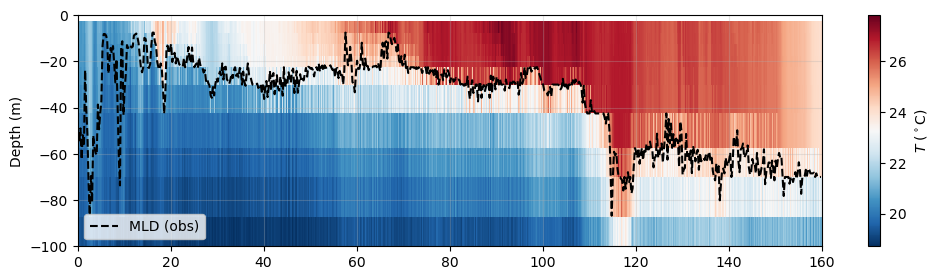

In [15]:
# --- Observations ---
t0 = met_start_day(MET_FILE)
t_obs, depth_s, T_obs = read_lotus_temp(TEMP_FILE, t0, N_DAYS)
mld_obs = mld_sensor(T_obs, depth_s)

edges = np.arange(0.0, N_DAYS + 1e-9, BIN_HOURS / 24)
t_bin = 0.5 * (edges[1:] + edges[:-1])
mld_obs_bin = bin_average(t_obs, mld_obs, edges)
 
fig, ax = plt.subplots(1, 1, figsize=(12, 3))

pc = ax.pcolormesh(t_obs, -depth_s, T_obs.T, cmap='RdBu_r', shading='nearest')
ax.plot(t_bin, -mld_obs_bin, 'k--', label='MLD (obs)')
ax.set_ylabel('Depth (m)')
ax.set_ylim(-depth_s[-1], 0)
fig.colorbar(pc, ax=ax, label=r'$T$ ($^\circ$C)')
ax.legend(loc='lower left')
ax.grid(alpha=0.3)

In [16]:
def _load(model_name, ne, var, level=None, sign=1, use_daily_mean=False):
    file_name = OUTPUT_FOLDER + f'lotus_stratif_{model_name}_ne{ne}.nc'
    with nc.Dataset(file_name) as data:
        t = data['time'][:] / 86400
        m = data[f'{var}_mean'][:]
        v = data[f'{var}_var'][:]
    if level is not None:
        m, v = m[:, level], v[:, level]
    m = sign * m

    if use_daily_mean:
        t_avg, m = daily_mean(t, m, N_DAYS)
        _,     v = daily_mean(t, v, N_DAYS)
        t = t_avg
    return t, m, v**0.5

def load_MLD(model_name, ne, **kw):
    return _load(model_name, ne, 'mld', sign=-1, **kw)

def load_SST(model_name, ne, **kw):
    return _load(model_name, ne, 'temp', level=0, **kw)

def epic_days(f):
    return f['time'][:].astype(float) + f['time2'][:].astype(float) / 86400e3

In [24]:
def closures_grid(load_fn, t_obs, y_obs, ylabel, title,
                  xlim=(0, 160), ylim=None, tag_loc='lower right'):
    fig, axes = plt.subplots(2, 3, figsize=(12, 5), sharex=True, sharey=True,
                             layout='constrained')

    # Position of the "(a) closure" tag inside each panel
    tx, ha = (0.97, 'right')
    ty, va = (0.95, 'top')

    for i, (ax, (key, label, color)) in enumerate(zip(axes.flat, CLOSURES)):
        t, m, s = load_fn(key, NENS)
        ax.fill_between(t, m - s, m + s, color=color, alpha=0.25, lw=0, zorder=2)
        ax.plot(t_obs, y_obs, 'k--', lw=1, zorder=4)
        ax.plot(t, m, color=color, lw=1.3, zorder=3)
        ax.text(tx, ty, f'({"abcdef"[i]}) {label}', transform=ax.transAxes,
                ha=ha, va=va, fontsize=11, color=color, fontweight='bold')
        ax.grid(alpha=0.3)

    axes[0, 0].set_xlim(*xlim)
    if ylim is not None:
        axes[0, 0].set_ylim(*ylim)
    for ax in axes[-1, :]:
        ax.set_xlabel('Time [days]')
    for ax in axes[:, 0]:
        ax.set_ylabel(ylabel)

    handles = [
        Line2D([], [], color='0.3', lw=1.3,      label='Ensemble mean'),
        Patch(facecolor='0.3', alpha=0.25,        label=r'Ensemble mean $\pm 1\sigma$'),
        Line2D([], [], color='k', ls='--', lw=1,  label='Observations'),
    ]
    fig.legend(handles=handles, loc='outside lower center', ncol=3, frameon=False)
    fig.suptitle(title)
    return fig, axes

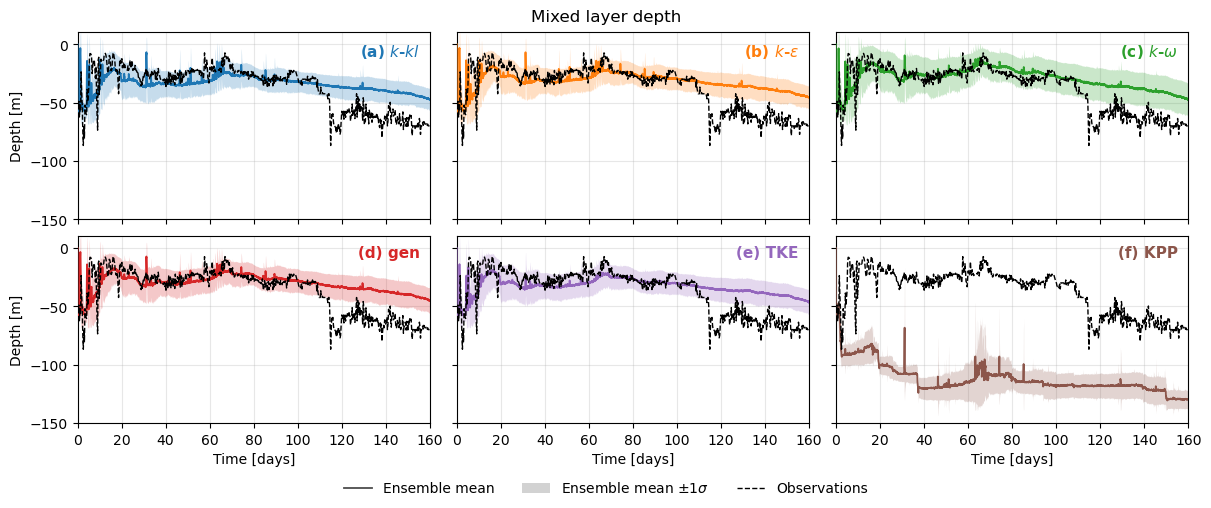

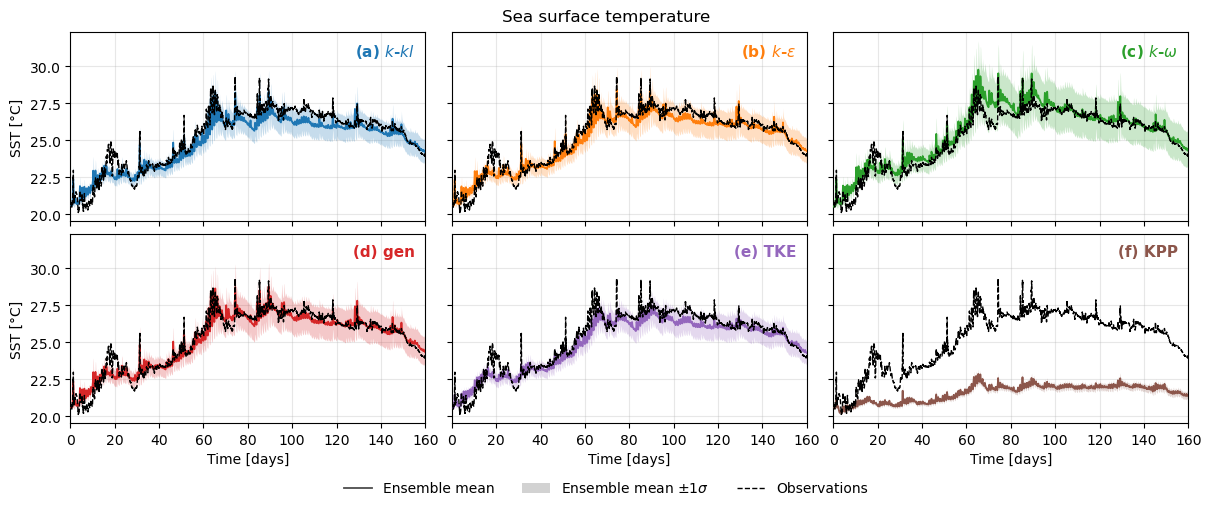

In [25]:
# ---------- Observed SST ----------
with nc.Dataset(MET_FILE) as f:
    f.set_auto_mask(False)
    t_met = epic_days(f)
    t_met -= t_met[0]
    sst = f['stmp'][:, 0, 0, 0].astype(np.float64)

sst[np.abs(sst) > 1e30] = np.nan
keep = (t_met >= 0) & (t_met <= N_DAYS)
t_met, sst = t_met[keep], sst[keep]
# t_met_d, sst_d = daily_mean(t_met, sst, N_DAYS)

# ---------- Figures ----------
fig_mld, _ = closures_grid(load_MLD, t_bin, -mld_obs_bin,
                           ylabel='Depth [m]', title='Mixed layer depth',
                           ylim=(-150, 10))

fig_sst, _ = closures_grid(load_SST, t_met, sst,
                           ylabel='SST [°C]', title='Sea surface temperature')

## To explaint the gap after 110 days

In [19]:
# --- Observed Temperature ---
with nc.Dataset(MET_FILE) as f:
    f.set_auto_mask(False)
    t0 = epic_days(f)[0]
    sst = f['stmp'][:, 0, 0, 0]
    
with nc.Dataset(TEMP_FILE) as f:
    f.set_auto_mask(False)
    t_obs = epic_days(f) - t0
    depth = np.abs(f['depth'][:])
    temp  = f['temp'][:, :, 0, 0]

# Depth values
order = np.argsort(depth)
depth, temp = depth[order], temp[:, order]

# Temperature values
temp[np.abs(temp) > 1e30] = np.nan
keep = (t_obs >= 0) & (t_obs <= N_DAYS)
t_obs, temp = t_obs[keep], temp[keep]

(0.0, 160.0)

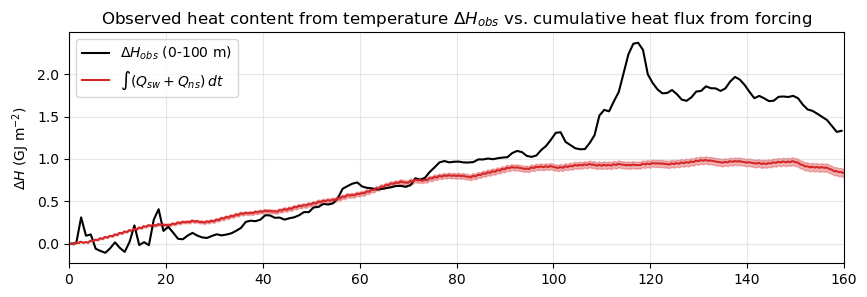

In [20]:
# --- Heat content 0-100 m ---
RHO_CP = 1000.0 * 3985.0
z_int = np.concatenate(([0.0], depth))
T_int = np.concatenate((temp[:, :1], temp), axis=1)
H_obs = RHO_CP * np.trapezoid(T_int, z_int, axis=1)
t_day, H_obs_d = daily_mean(t_obs, H_obs, N_DAYS)
dH_obs = H_obs_d - H_obs_d[0]

# --- Cumulative surface flux from forcing ---
with np.load(os.path.join(OUTPUT_FOLDER, 'lotus_forcing.npz')) as fz:
    Qns, Qsw, dt = fz['Q_ns'], fz['Q_sw'], float(fz['dt'])
t_f   = np.arange(Qns.shape[1]) * dt / 86400
Q_net = Qns + Qsw[None, :]
dH_f  = np.cumsum(Q_net, axis=1) * dt
dH_f_m, dH_f_s = dH_f.mean(0), dH_f.std(0)

GJ = 1e9

fig, ax = plt.subplots(1, 1, figsize=(10, 3))
ax.set_title(r'Observed heat content from temperature $\Delta H_{obs}$ vs. cumulative heat flux from forcing')

# Observed heat content
ax.plot(t_day, dH_obs / GJ, 'k', label=r'$\Delta H_{obs}$ (0-100 m)')

# Cumulative heat fluxes
ax.plot(t_f, dH_f_m / GJ, 'C3', label=r'$\int (Q_{sw}+Q_{ns})\,dt$')
ax.fill_between(t_f, (dH_f_m - dH_f_s) / GJ, (dH_f_m + dH_f_s) / GJ,
                color='C3', alpha=0.35)

ax.set_ylabel(r'$\Delta H$ (GJ m$^{-2}$)')
ax.legend(loc='upper left')

ax.grid(alpha=0.3)
ax.set_xlim(0, N_DAYS)

In [21]:
# def plot_MLD_model(model_name, ne, label = None, color = 'C0', daily_mean = False):
#     file_name = OUTPUT_FOLDER + f'lotus_stratif_{model_name}_ne{ne}.nc'
    
#     with nc.Dataset(file_name) as data:
#         t   = data['time'][:] / 86400 # In days
#         mld_m  = -data[f'mld_mean'][:]
#         mld_v  = data[f'mld_var'][:]

#     if daily_mean:
#         t, mld_m = daily_mean(t, mld_m, N_DAYS)
#         t, mld_v = daily_mean(t, mld_v, N_DAYS)

#     plt.plot(t, mld_m, label = label, color = color)
#     plt.fill_between(t, mld_m + mld_v**0.5, mld_m - mld_v**0.5, color = color, alpha = 0.2)

# plt.figure(figsize=(12, 6))

# plt.subplot(211)
# plt.title('Mixed layer depth')
# plt.ylabel('Depth [m]')

# # Model
# plot_MLD_model('k-kl',      NENS, r'$k-kl$',          'C0')
# plot_MLD_model('k-epsilon', NENS, r'$k-\varepsilon$', 'C1')
# plot_MLD_model('k-omega',   NENS, r'$gen$',           'C2')

# # REF
# plt.plot(t_bin, -mld_obs_bin, 'k--', label='MLD (obs)')
# plt.ylim(-150, 10)
# plt.xlim(0, 160)
# plt.legend()
# plt.grid()

# plt.subplot(212)
# plt.xlabel('Time [days]')
# plt.ylabel('Depth [m]')

# plot_MLD_model('gen', NENS, r'$k-\omega$', 'C3')
# plot_MLD_model('tke', NENS, r'$TKE$',  'C4')
# plot_MLD_model('kpp', NENS, r'$KPP$',  'C5')

# # REF
# plt.plot(t_bin, -mld_obs_bin, 'k--', label='MLD (obs)')
# plt.ylim(-150, 10)
# plt.xlim(0, 160)
# plt.legend()
# plt.grid()

In [22]:
# def plot_SST_model(model_name, ne, label = None, color = 'C0', daily_mean = False):
#     file_name = OUTPUT_FOLDER + f'lotus_stratif_{model_name}_ne{ne}.nc'
    
#     with nc.Dataset(file_name) as data:
#         t   = data['time'][:] / 86400 # In days
#         sst_m  = data[f'temp_mean'][:, 0]
#         sst_v  = data[f'temp_var'][:, 0]
        
#     if daily_mean:
#         t, sst_m = daily_mean(t, sst_m, N_DAYS)
#         t, sst_v = daily_mean(t, sst_v, N_DAYS)
    
#     plt.plot(t, sst_m, label = label, color = color)
#     plt.fill_between(t, sst_m + sst_v**0.5, sst_m - sst_v**0.5, color = color, alpha = 0.2)

# # --- Observed SST ---
# with nc.Dataset(MET_FILE) as f:
#     f.set_auto_mask(False)
#     t_met = epic_days(f)
#     t_met -= t_met[0]
#     sst = f['stmp'][:, 0, 0, 0].astype(np.float64)

# sst[np.abs(sst) > 1e30] = np.nan
# keep = (t_met >= 0) & (t_met <= N_DAYS)
# t_met, sst = t_met[keep], sst[keep]
# t_met_d, sst_d = daily_mean(t_met, sst, N_DAYS)

# plt.figure(figsize=(10, 6))
# plt.suptitle('Sea surface temperature SST')

# plt.subplot(211)
# # Model
# plot_SST_model('k-kl',      NENS, r'$k-kl$',          'C0')
# plot_SST_model('k-epsilon', NENS, r'$k-\varepsilon$', 'C1')
# plot_SST_model('k-omega',   NENS, r'$gen$',           'C2')
# # REF
# plt.plot(t_met_d, sst_d, 'k--', label='SST (obs)')

# plt.ylabel(r'$SST [°C]$')
# plt.legend()
# plt.grid()

# plt.subplot(212)
# # Model
# plot_SST_model('gen', NENS, r'$gen$', 'C3')
# plot_SST_model('tke', NENS, r'$TKE$', 'C4')
# plot_SST_model('kpp', NENS, r'$KPP$', 'C5')
# # REF
# plt.plot(t_met_d, sst_d, 'k--', label='SST (obs)')

# plt.ylabel(r'$SST [°C]$')
# plt.legend()
# plt.grid()